# 결론 7 — H3 다시 세우기 (방향 공백)

`report_08`의 H3(직통 노선 수 ↔ 거리 보정 출근 시간)는 **두 그룹 차이가 약 1분**이라 실제 의미가 작았다.
유동인구 시간은 모든 교통수단이 섞이고, **실제로 이동한 사람만** 잡힌다(추정).
그래서 H3을 **버스 노선도 기준 '방향 공백'** 으로 바꾼다. 옛 H3는 과정 기록으로 남긴다.

**새 H3**: 관악 정류장은 다른 구 정류장보다, 출근 1위 목적지행 멀리 가는 노선이
**도보 300m 안에도 없는 비율(방향 공백)** 이 높았나

- 대상·정의는 `con_5_gap25`(= report_08 3단계) 그대로:
  구마다 **월 승차 ≥ 75퍼센타일 + 가장 가까운 지하철역 300m 밖** 정류장,
  그 구의 **출근(도착 7~9시·평일·HW) 목적지 1위 구**를 지나는 멀리 가는 노선이
  도보 300m 안에 **0개**면 공백
- `con_5`와 다른 점: 구 단위 비율의 **순위**가 아니라 **정류장 단위 0/1**로 검정한다

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import biv_stats as bs
from bus_util import ARS2GU, FAR, GU_ORDER, P75, haversine_m

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 250)

HL = "관악구"
RS = [200, 300, 500]
R_MAIN = 300

stop = pd.read_csv(PROC / "stop_metrics_subway.csv", encoding="utf-8-sig",
                   dtype={"버스정류장ARS번호": str})
sr = pd.read_csv(PROC / "stop_route.csv", encoding="utf-8-sig",
                 dtype={"ARS": str, "노선번호": str})
order = pd.read_csv(PROC / "route_order.csv", encoding="utf-8-sig",
                    dtype={"ARS": str, "노선번호": str})
pairs = pd.read_csv(PROC / "fin_h3_pairs.csv", encoding="utf-8-sig")
walk = pd.read_csv(PROC / "stop_walk.csv", encoding="utf-8-sig", dtype={"ARS": str})
print(stop.shape, sr.shape, order.shape, pairs.shape, walk.shape)

(10615, 24) (33992, 7) (37694, 6) (600, 13) (10606, 22)


In [3]:
# con_5_gap25와 같은 전처리: 좌표 · 정류장별 멀리 가는 노선 집합 · 구별 경유 노선 집합
attr = (stop.rename(columns={"버스정류장ARS번호": "ARS", "월승차": "정류장월승차"})
        [["ARS", "정류장명", "자치구", "정류장월승차", "멀리가는노선수",
          "가까운역거리m", "경도", "위도"]].copy())
cod = attr.dropna(subset=["위도", "경도"]).reset_index(drop=True)
lat = cod["위도"].to_numpy(float)
lon = cod["경도"].to_numpy(float)
ars = cod["ARS"].to_numpy()
pos = {a: i for i, a in enumerate(ars)}

fset = sr[sr["노선종류"].isin(FAR)].groupby("ARS")["노선번호"].apply(frozenset)
rsets = [fset.get(a, frozenset()) for a in ars]

far_type = sr.drop_duplicates("노선번호").set_index("노선번호")["노선종류"]
ro = order.assign(자치구=order["ARS"].str[:2].map(ARS2GU))
rgu = (ro[ro["노선번호"].isin(far_type[far_type.isin(FAR)].index)]
       .groupby("노선번호")["자치구"].apply(lambda s: frozenset(s.dropna())))
passes = {g: {r for r, s in rgu.items() if g in s} for g in GU_ORDER}
print("좌표 있는 정류장:", len(cod), "/ 멀리 가는 노선:", len(rgu))

좌표 있는 정류장: 10606 / 멀리 가는 노선: 343


## 1. 구별 출근 목적지 1~3위 + 대상 정류장

`fin_h3_pairs.csv` 재사용 — **도착 7~9시 · 평일 · 이동유형 HW(집→직장) · 출발≠도착**.

In [4]:
rows = []
for g in GU_ORDER:
    d = (pairs[pairs["출발구"] == g].set_index("도착구")["이동인구"]
         .sort_values(ascending=False))
    tot = d.sum()
    rec = {"자치구": g}
    for k in range(3):
        rec[f"{k + 1}위"] = d.index[k]
        rec[f"{k + 1}위비중"] = d.iloc[k] / tot
    rows.append(rec)
dest = pd.DataFrame(rows).set_index("자치구")
print(dest.round(3).to_string())

        1위   1위비중    2위   2위비중    3위   3위비중
자치구                                        
종로구     중구  0.233   강남구  0.097  서대문구  0.092
중구     종로구  0.155   강남구  0.136   성동구  0.128
용산구     중구  0.172   강남구  0.134   서초구  0.105
성동구    강남구  0.202    중구  0.162   종로구  0.085
광진구    강남구  0.237   성동구  0.149   송파구  0.105
동대문구    중구  0.127   성동구  0.126   강남구  0.121
중랑구    강남구  0.165  동대문구  0.125   노원구  0.091
성북구    종로구  0.167    중구  0.137   강북구  0.096
강북구    성북구  0.156    중구  0.130   종로구  0.112
도봉구    노원구  0.175   강북구  0.139    중구  0.106
노원구    강남구  0.121    중구  0.101   도봉구  0.094
은평구    마포구  0.143  서대문구  0.140    중구  0.132
서대문구   마포구  0.169    중구  0.150   종로구  0.144
마포구   영등포구  0.143  서대문구  0.142    중구  0.136
양천구    강서구  0.213  영등포구  0.196   구로구  0.086
강서구   영등포구  0.207   양천구  0.154   강남구  0.094
구로구   영등포구  0.189   금천구  0.124   강남구  0.109
금천구    구로구  0.176   관악구  0.143  영등포구  0.131
영등포구   강남구  0.129    중구  0.099   구로구  0.092
동작구    서초구  0.185   강남구  0.175  영등포구  0.125
관악구    강남구  0.226   서초구  0.178  

In [5]:
# 대상: 월 승차 >= P75 + 역 300m 밖. 반경별 도보권 멀리 가는 노선 합집합
tgt = cod[(cod["정류장월승차"] >= P75) & (cod["가까운역거리m"] > 300)].copy()
uni = {R: [] for R in RS}
for a in tgt["ARS"]:
    i = pos[a]
    d = haversine_m(lat[i], lon[i], lat, lon)
    for R in RS:
        uni[R].append(frozenset().union(*[rsets[j] for j in np.flatnonzero(d <= R)]))
for R in RS:
    tgt[f"도보{R}_노선"] = uni[R]
    tgt[f"도보{R}_노선수"] = [len(u) for u in uni[R]]
print(f"대상 정류장: {len(tgt)}개 (관악 {int((tgt['자치구'] == HL).sum())} / "
      f"나머지 {int((tgt['자치구'] != HL).sum())})")
print("도보권 멀리 가는 노선 수 중앙값:",
      {R: int(tgt[f'도보{R}_노선수'].median()) for R in RS})

대상 정류장: 1489개 (관악 107 / 나머지 1382)
도보권 멀리 가는 노선 수 중앙값: {200: 6, 300: 8, 500: 11}


In [6]:
# 정류장 단위 공백 여부(0/1) — 자기 구 출근 1위 목적지 기준
def gap_flags(df, R):
    out = []
    for gu, u in zip(df["자치구"], df[f"도보{R}_노선"]):
        out.append(int(len(u & passes[dest.loc[gu, "1위"]]) == 0))
    return np.array(out)


for R in RS:
    tgt[f"공백_{R}"] = gap_flags(tgt, R)

stop_tbl = (tgt.assign(출근1위=tgt["자치구"].map(dest["1위"]))
            .rename(columns={"정류장월승차": "월승차",
                             f"도보{R_MAIN}_노선수": "도보300m_멀리노선수",
                             "멀리가는노선수": "자기정류장_멀리노선수",
                             f"공백_{R_MAIN}": "공백"})
            [["자치구", "ARS", "정류장명", "출근1위", "월승차", "공백",
              "도보300m_멀리노선수", "자기정류장_멀리노선수"]]
            .sort_values(["자치구", "월승차"], ascending=[True, False])
            .reset_index(drop=True))
print(stop_tbl.groupby("자치구")["공백"].agg(["size", "sum", "mean"]).round(3).to_string())
stop_tbl.head(15)

      size  sum   mean
자치구                   
강남구    104    2  0.019
강동구     36    1  0.028
강북구     38    0  0.000
강서구     50    0  0.000
관악구    107   86  0.804
광진구     33    9  0.273
구로구     59    3  0.051
금천구     68    4  0.059
노원구     55   27  0.491
도봉구     52    8  0.154
동대문구    81    4  0.049
동작구     48   18  0.375
마포구     46    9  0.196
서대문구    83    5  0.060
서초구     67    1  0.015
성동구     35    1  0.029
성북구     82   12  0.146
송파구     53    2  0.038
양천구     77    5  0.065
영등포구    73   39  0.534
용산구     55    2  0.036
은평구     68    7  0.103
종로구     46    1  0.022
중구      15    0  0.000
중랑구     58    3  0.052


,자치구,ARS,정류장명,출근1위,월승차,공백,도보300m_멀리노선수,자기정류장_멀리노선수
0,강남구,23370,삼호물산,서초구,76146,0,5,3
1,강남구,23167,프리마호텔,서초구,75411,0,8,8
2,강남구,23102,신사중학교,서초구,74444,0,8,7
3,강남구,23263,은마아파트입구사거리,서초구,62248,0,10,5
4,강남구,23166,프리마호텔,서초구,61484,0,9,7
5,강남구,23507,영동고등학교현대아파트,서초구,55953,0,8,5
6,강남구,23217,포스코건너편,서초구,54923,0,10,5
7,강남구,23161,씨네시티.앞,서초구,47638,0,9,5
8,강남구,23224,농협대치지점,서초구,46748,0,10,9
9,강남구,23307,진선여자중고등학교,서초구,45809,0,11,5


## 2. 메인 검정 — 관악 vs 나머지 24개 구 (정류장 단위 공백 비율)

**귀무**: 관악 정류장과 나머지 구 정류장의 방향 공백 비율은 차이가 없다
**대립**: 관악이 **더 높다** (양쪽 검정으로 보고, 방향은 비율로 확인)

In [7]:
# 2x2 공백 비율 검정. 기대빈도 5 미만 칸이 있으면 Fisher
def chi_2x2(a_gap, a_n, b_gap, b_n, la="관악", lb="나머지"):
    tbl = np.array([[a_gap, a_n - a_gap], [b_gap, b_n - b_gap]])
    chi2, p_chi, dof, exp = stats.chi2_contingency(tbl, correction=False)
    small = int((exp < 5).sum())
    if small:
        method, p = "Fisher 정확검정", stats.fisher_exact(tbl)[1]
    else:
        method, p = "카이제곱", p_chi
    return {"비교": f"{la} vs {lb}", "방법": method,
            "n_관악": a_n, "n_상대": b_n,
            "공백비율_관악": round(a_gap / a_n, 3),
            "공백비율_상대": round(b_gap / b_n, 3),
            "차이": round(a_gap / a_n - b_gap / b_n, 3),
            "기대빈도5미만칸": small, "p표시": bs.ptxt(p), "별표": bs.star(p) or "n.s.",
            "유의": p < 0.05, "_tbl": tbl}


A = stop_tbl[stop_tbl["자치구"] == HL]
B = stop_tbl[stop_tbl["자치구"] != HL]
main = chi_2x2(int(A["공백"].sum()), len(A), int(B["공백"].sum()), len(B),
               lb="나머지 24개 구")
print("2x2 표")
print(pd.DataFrame(main["_tbl"], index=["관악", "나머지 24개 구"],
                   columns=["공백", "비공백"]).to_string())
print(f"\n관악 {int(A['공백'].sum())}/{len(A)} = {A['공백'].mean():.3f}  vs  "
      f"나머지 {int(B['공백'].sum())}/{len(B)} = {B['공백'].mean():.3f}")
print(f"{main['방법']} → {main['p표시']} {main['별표']} "
      f"(차이 {main['차이']:+.3f}, {A['공백'].mean() / B['공백'].mean():.2f}배)")

2x2 표
            공백   비공백
관악          86    21
나머지 24개 구  163  1219

관악 86/107 = 0.804  vs  나머지 163/1382 = 0.118
카이제곱 → p<0.05 ** (차이 +0.686, 6.81배)


In [8]:
# 보조: 관악 vs 공백 비율 2위 구만
RUNNER = stop_tbl[stop_tbl["자치구"] != HL].groupby("자치구")["공백"].mean().idxmax()
C = stop_tbl[stop_tbl["자치구"] == RUNNER]
sub = chi_2x2(int(A["공백"].sum()), len(A), int(C["공백"].sum()), len(C), lb=RUNNER)
print(f"공백 비율 2위 구 = {RUNNER} ({C['공백'].mean():.3f})")
main_tbl = pd.DataFrame([{k: v for k, v in r.items() if k != "_tbl"}
                         for r in [main, sub]])
main_tbl

공백 비율 2위 구 = 영등포구 (0.534)


,비교,방법,n_관악,n_상대,공백비율_관악,공백비율_상대,차이,기대빈도5미만칸,p표시,별표,유의
0,관악 vs 나머지 24개 구,카이제곱,107,1382,0.804,0.118,0.686,0,p<0.05,**,True
1,관악 vs 영등포구,카이제곱,107,73,0.804,0.534,0.269,0,p<0.05,**,True


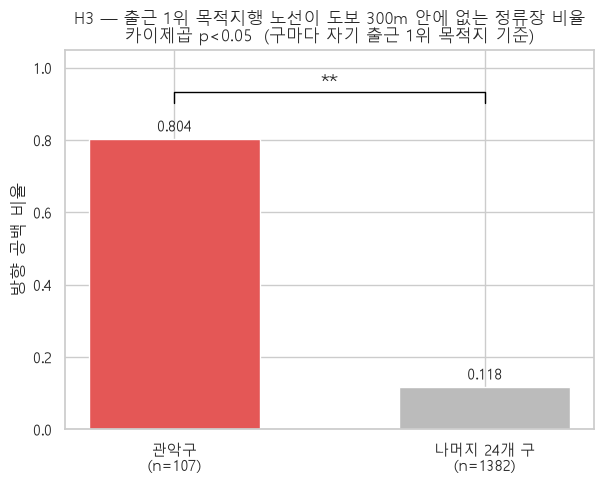

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 5))
vals = [A["공백"].mean(), B["공백"].mean()]
labs = [f"{HL}\n(n={len(A)})", f"나머지 24개 구\n(n={len(B)})"]
ax.bar(labs, vals, color=["#E45756", "#bbbbbb"], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=11)
y = max(vals) + 0.1
ax.plot([0, 0, 1, 1], [y, y + 0.03, y + 0.03, y], color="black", lw=1)
ax.text(0.5, y + 0.04, main["별표"], ha="center", fontsize=14)
ax.set_ylim(0, 1.05)
ax.set_ylabel("방향 공백 비율")
ax.set_title(f"H3 — 출근 1위 목적지행 노선이 도보 {R_MAIN}m 안에 없는 정류장 비율\n"
             f"{main['방법']} {main['p표시']}  (구마다 자기 출근 1위 목적지 기준)")
plt.tight_layout()
plt.show()

## 3. "노선이 적어서 당연한 거 아냐?" 막기

관악에 **버스가 적어서** 공백이 많은 거라면 결론이 달라진다.
그래서 **도보 300m 안 멀리 가는 노선 수** 자체를 비교한다.
관악이 **적지 않다면** 버스 수가 아니라 **방향** 문제라는 근거가 된다.

In [10]:
# (1) 대상 정류장 전체 — 도보 300m 안 멀리 가는 노선 수
col = "도보300m_멀리노선수"
g_all = bs.group2(A[col], B[col], HL, "나머지", col)
print(g_all)
print(f"\n→ 중앙값 {HL} {g_all['중앙값_관악구']} vs 나머지 {g_all['중앙값_나머지']} "
      f"/ {g_all['방법']} {g_all['p표시']} {g_all['별표'] or 'n.s.'}")

{'변수': '도보300m_멀리노선수', '방법': '순위합 검정(W)', 'n_관악구': 107, 'n_나머지': 1382, '중앙값_관악구': 10.0, '중앙값_나머지': 8.0, '평균_관악구': 9.0841, '평균_나머지': 9.0224, 'p표시': 'p>0.05', '별표': '', '유의': np.False_, '정규성_관악구': 'p<0.05', '정규성_나머지': 'p<0.05', 'Levene': '-'}

→ 중앙값 관악구 10.0 vs 나머지 8.0 / 순위합 검정(W) p>0.05 n.s.


In [11]:
# (2) 공백 정류장끼리만
Ag = A[A["공백"] == 1]
Bg = B[B["공백"] == 1]
g_gap = bs.group2(Ag[col], Bg[col], HL, "나머지", col + " (공백끼리)")
print(g_gap)
print(f"\n→ 공백끼리: {HL} {g_gap['중앙값_관악구']} (n={g_gap['n_관악구']}) vs "
      f"나머지 {g_gap['중앙값_나머지']} (n={g_gap['n_나머지']}) "
      f"/ {g_gap['방법']} {g_gap['p표시']} {g_gap['별표'] or 'n.s.'}")
route_cmp = pd.DataFrame([{k: v for k, v in d.items() if k != "유의"}
                          for d in [g_all, g_gap]])
route_cmp

{'변수': '도보300m_멀리노선수 (공백끼리)', '방법': '순위합 검정(W)', 'n_관악구': 86, 'n_나머지': 163, '중앙값_관악구': 7.0, '중앙값_나머지': 4.0, '평균_관악구': 8.2907, '평균_나머지': 5.4356, 'p표시': 'p<0.05', '별표': '**', '유의': np.True_, '정규성_관악구': 'p<0.05', '정규성_나머지': 'p<0.05', 'Levene': '-'}

→ 공백끼리: 관악구 7.0 (n=86) vs 나머지 4.0 (n=163) / 순위합 검정(W) p<0.05 **


,변수,방법,n_관악구,n_나머지,중앙값_관악구,중앙값_나머지,평균_관악구,평균_나머지,p표시,별표,정규성_관악구,정규성_나머지,Levene
0,도보300m_멀리노선수,순위합 검정(W),107,1382,10.0,8.0,9.0841,9.0224,p>0.05,,p<0.05,p<0.05,-
1,도보300m_멀리노선수 (공백끼리),순위합 검정(W),86,163,7.0,4.0,8.2907,5.4356,p<0.05,**,p<0.05,p<0.05,-


In [12]:
# (3) 층별 — 도보권 노선 수가 같은 층 안에서도 관악 공백이 높은가
BANDS = [(0, 2, "0~2"), (3, 5, "3~5"), (6, 9, "6~9"), (10, 10 ** 6, "10+")]
rows = []
for lo, hi, lab in BANDS:
    a = A[(A[col] >= lo) & (A[col] <= hi)]
    b = B[(B[col] >= lo) & (B[col] <= hi)]
    rec = {"층(도보300m 멀리노선수)": lab, "n_관악": len(a), "n_나머지": len(b),
           "공백비율_관악": round(a["공백"].mean(), 3) if len(a) else np.nan,
           "공백비율_나머지": round(b["공백"].mean(), 3) if len(b) else np.nan}
    if len(a) >= 10 and len(b) >= 10:
        r = chi_2x2(int(a["공백"].sum()), len(a), int(b["공백"].sum()), len(b))
        rec["방법"], rec["p표시"], rec["별표"] = r["방법"], r["p표시"], r["별표"]
    else:
        rec["방법"] = rec["p표시"] = rec["별표"] = "n<10 판단 보류"
    rows.append(rec)
layer = pd.DataFrame(rows)
layer

,층(도보300m 멀리노선수),n_관악,n_나머지,공백비율_관악,공백비율_나머지,방법,p표시,별표
0,0~2,8,108,1.000,0.593,n<10 판단 보류,n<10 판단 보류,n<10 판단 보류
1,3~5,19,306,1.000,0.118,Fisher 정확검정,p<0.05,**
2,6~9,26,443,0.769,0.065,Fisher 정확검정,p<0.05,**
3,10+,54,525,0.722,0.065,카이제곱,p<0.05,**


In [13]:
# (4) 예시 — 관악 공백 정류장 중 도보권 노선이 많은 5곳, 그 노선들이 가는 구
ex = (tgt[(tgt["자치구"] == HL) & (tgt[f"공백_{R_MAIN}"] == 1)]
      .sort_values(f"도보{R_MAIN}_노선수", ascending=False).head(5))
rows = []
for _, r in ex.iterrows():
    cnt = {}
    for rt in r[f"도보{R_MAIN}_노선"]:
        for g in rgu.get(rt, frozenset()):
            if g != HL:
                cnt[g] = cnt.get(g, 0) + 1
    top3 = sorted(cnt.items(), key=lambda kv: -kv[1])[:3]
    rows.append({"정류장명": r["정류장명"], "ARS": r["ARS"],
                 "월승차": int(r["정류장월승차"]),
                 "도보300m_멀리노선수": r[f"도보{R_MAIN}_노선수"],
                 "그 노선들이 가는 구 상위 3": ", ".join(f"{g} {c}개" for g, c in top3),
                 f"{dest.loc[HL, '1위']} 가는 노선": cnt.get(dest.loc[HL, "1위"], 0)})
example = pd.DataFrame(rows)
print(f"※ {HL} 출근 1위 목적지 = {dest.loc[HL, '1위']} ({dest.loc[HL, '1위비중']:.1%})")
example

※ 관악구 출근 1위 목적지 = 강남구 (22.6%)


,정류장명,ARS,월승차,도보300m_멀리노선수,그 노선들이 가는 구 상위 3,강남구 가는 노선
0,동부아파트,21677,13509,19,"동작구 14개, 금천구 11개, 구로구 6개",0
1,난곡입구,21111,26146,17,"금천구 12개, 동작구 12개, 구로구 7개",0
2,신림청소년독서실.신림체육센터,21219,19326,17,"금천구 12개, 동작구 12개, 구로구 7개",0
3,신림청소년독서실.신림체육센터,21204,14118,17,"금천구 12개, 동작구 12개, 구로구 7개",0
4,난곡입구,21115,64668,17,"금천구 12개, 동작구 12개, 구로구 7개",0


## 4. 견고성

1) 반경 **200m·500m** / 2) 목적지 **1~3위 비중 가중** 공백 / 3) 의존 정류장 정의를 **walk300**으로

In [14]:
# (1) 반경 200·500m에서 메인 검정 반복
rob = []
for R in RS:
    a = tgt[tgt["자치구"] == HL][f"공백_{R}"]
    b = tgt[tgt["자치구"] != HL][f"공백_{R}"]
    r = chi_2x2(int(a.sum()), len(a), int(b.sum()), len(b))
    rob.append({"버전": f"반경 {R}m" + (" (메인)" if R == R_MAIN else ""),
                "공백비율_관악": r["공백비율_관악"], "공백비율_나머지": r["공백비율_상대"],
                "n_관악": len(a), "n_나머지": len(b),
                "검정": r["방법"], "p표시": r["p표시"], "별표": r["별표"]})
pd.DataFrame(rob)

,버전,공백비율_관악,공백비율_나머지,n_관악,n_나머지,검정,p표시,별표
0,반경 200m,0.832,0.158,107,1382,카이제곱,p<0.05,**
1,반경 300m (메인),0.804,0.118,107,1382,카이제곱,p<0.05,**
2,반경 500m,0.785,0.062,107,1382,카이제곱,p<0.05,**


In [15]:
# (2) 목적지 1~3위 비중 가중 공백 — 정류장마다 0~1 연속값
w_vals = []
for gu, u in zip(tgt["자치구"], tgt[f"도보{R_MAIN}_노선"]):
    ws = np.array([dest.loc[gu, f"{k}위비중"] for k in [1, 2, 3]], float)
    gs = np.array([int(len(u & passes[dest.loc[gu, f"{k}위"]]) == 0) for k in [1, 2, 3]])
    w_vals.append(float((ws * gs).sum() / ws.sum()))
tgt["공백_가중"] = w_vals

gw = bs.group2(tgt.loc[tgt["자치구"] == HL, "공백_가중"],
               tgt.loc[tgt["자치구"] != HL, "공백_가중"], HL, "나머지", "가중 공백")
print(gw)
rob.append({"버전": "목적지 1~3위 비중 가중",
            "공백비율_관악": gw["평균_관악구"], "공백비율_나머지": gw["평균_나머지"],
            "n_관악": gw["n_관악구"], "n_나머지": gw["n_나머지"],
            "검정": gw["방법"], "p표시": gw["p표시"], "별표": gw["별표"] or "n.s."})
print(f"\n→ 평균 가중 공백 {HL} {gw['평균_관악구']} vs 나머지 {gw['평균_나머지']} "
      f"/ {gw['방법']} {gw['p표시']} {gw['별표'] or 'n.s.'}")

{'변수': '가중 공백', '방법': '순위합 검정(W)', 'n_관악구': 107, 'n_나머지': 1382, '중앙값_관악구': 0.4579, '중앙값_나머지': 0.0, '평균_관악구': 0.4811, '평균_나머지': 0.1431, 'p표시': 'p<0.05', '별표': '**', '유의': np.True_, '정규성_관악구': 'p<0.05', '정규성_나머지': 'p<0.05', 'Levene': '-'}

→ 평균 가중 공백 관악구 0.4811 vs 나머지 0.1431 / 순위합 검정(W) p<0.05 **


In [16]:
# (3) 의존 정류장 정의를 walk300으로 바꾼 대상에서 반복
wk = set(walk.loc[walk["도보권의존_300"].astype(bool), "ARS"])
W = tgt[tgt["ARS"].isin(wk)].copy()
aw = W[W["자치구"] == HL][f"공백_{R_MAIN}"]
bw = W[W["자치구"] != HL][f"공백_{R_MAIN}"]
print(f"walk300 의존 정류장: 전체 {len(W)}개 (관악 {len(aw)} / 나머지 {len(bw)})")
print("구별:", W.groupby("자치구").size().to_dict())

if len(aw) >= 10 and len(bw) >= 10:
    r = chi_2x2(int(aw.sum()), len(aw), int(bw.sum()), len(bw))
    rob.append({"버전": "walk300 의존 정류장", "공백비율_관악": r["공백비율_관악"],
                "공백비율_나머지": r["공백비율_상대"], "n_관악": len(aw),
                "n_나머지": len(bw), "검정": r["방법"], "p표시": r["p표시"],
                "별표": r["별표"]})
    print(f"→ {r['방법']} {r['p표시']} {r['별표']}")
else:
    rob.append({"버전": "walk300 의존 정류장",
                "공백비율_관악": round(float(aw.mean()), 3) if len(aw) else np.nan,
                "공백비율_나머지": round(float(bw.mean()), 3) if len(bw) else np.nan,
                "n_관악": len(aw), "n_나머지": len(bw),
                "검정": "n<10 판단 보류", "p표시": "-", "별표": "-"})
    print("→ 대상 수가 적어 판단 보류")
rob_tbl = pd.DataFrame(rob)
rob_tbl

walk300 의존 정류장: 전체 66개 (관악 8 / 나머지 58)
구별: {'강동구': 2, '관악구': 8, '구로구': 3, '금천구': 4, '노원구': 4, '도봉구': 1, '동작구': 7, '마포구': 2, '서대문구': 5, '서초구': 8, '성동구': 1, '성북구': 6, '송파구': 2, '양천구': 4, '영등포구': 3, '용산구': 1, '은평구': 1, '종로구': 2, '중구': 2}
→ 대상 수가 적어 판단 보류


,버전,공백비율_관악,공백비율_나머지,n_관악,n_나머지,검정,p표시,별표
0,반경 200m,0.8320,0.1580,107,1382,카이제곱,p<0.05,**
1,반경 300m (메인),0.8040,0.1180,107,1382,카이제곱,p<0.05,**
2,반경 500m,0.7850,0.0620,107,1382,카이제곱,p<0.05,**
3,목적지 1~3위 비중 가중,0.4811,0.1431,107,1382,순위합 검정(W),p<0.05,**
4,walk300 의존 정류장,1.0000,0.7410,8,58,n<10 판단 보류,-,-


## 결론

In [17]:
print(f"1) 메인: {HL} {A['공백'].mean():.3f} ({int(A['공백'].sum())}/{len(A)}) vs "
      f"나머지 24개 구 {B['공백'].mean():.3f} ({int(B['공백'].sum())}/{len(B)}) "
      f"→ {main['방법']} {main['p표시']} {main['별표']}")
print(f"2) 보조: {HL} vs {RUNNER} {C['공백'].mean():.3f} "
      f"→ {sub['방법']} {sub['p표시']} {sub['별표']}")
print(f"3) 도보 {R_MAIN}m 멀리 가는 노선 수: {HL} 중앙값 {g_all['중앙값_관악구']} vs "
      f"나머지 {g_all['중앙값_나머지']} ({g_all['방법']} {g_all['p표시']}) → "
      f"{'관악이 적지 않다 = 방향 문제' if g_all['중앙값_관악구'] >= g_all['중앙값_나머지'] else '관악이 더 적다 = 해석 주의'}")
print(f"4) 층별: 판단한 층 {int((layer['p표시'] != 'n<10 판단 보류').sum())}개 중 "
      f"p<0.05 {int((layer['p표시'] == 'p<0.05').sum())}개 / "
      f"관악이 더 높은 층 {int((layer['공백비율_관악'] > layer['공백비율_나머지']).sum())}/{len(layer)}")
print(f"5) 견고성 {len(rob_tbl)}개 버전 중 p<0.05 "
      f"{int((rob_tbl['p표시'] == 'p<0.05').sum())}개, 판단 보류 "
      f"{int((rob_tbl['검정'] == 'n<10 판단 보류').sum())}개")

1) 메인: 관악구 0.804 (86/107) vs 나머지 24개 구 0.118 (163/1382) → 카이제곱 p<0.05 **
2) 보조: 관악구 vs 영등포구 0.534 → 카이제곱 p<0.05 **
3) 도보 300m 멀리 가는 노선 수: 관악구 중앙값 10.0 vs 나머지 8.0 (순위합 검정(W) p>0.05) → 관악이 적지 않다 = 방향 문제
4) 층별: 판단한 층 3개 중 p<0.05 3개 / 관악이 더 높은 층 4/4
5) 견고성 5개 버전 중 p<0.05 4개, 판단 보류 1개


In [18]:
stop_tbl.to_csv(PROC / "fin_h3gap_stops.csv", index=False, encoding="utf-8-sig")
main_tbl.to_csv(PROC / "fin_h3gap_main.csv", index=False, encoding="utf-8-sig")
route_cmp.to_csv(PROC / "fin_h3gap_routecnt.csv", index=False, encoding="utf-8-sig")
layer.to_csv(PROC / "fin_h3gap_layer.csv", index=False, encoding="utf-8-sig")
example.to_csv(PROC / "fin_h3gap_example.csv", index=False, encoding="utf-8-sig")
rob_tbl.to_csv(PROC / "fin_h3gap_robust.csv", index=False, encoding="utf-8-sig")
print("저장 완료")

저장 완료
